In [38]:
import pandas as pd
df = pd.read_csv("netflix_titles.csv")
df.shape



(8807, 12)

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [40]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


**Finding:** Movies make up 69.6% of the catalog and TV Shows make up 30.4%.

In [41]:
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Unknown")

df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), errors="coerce")
df["year_added"] = df["date_added"].dt.year

df = df.drop_duplicates()

df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)

df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,3


**Finding:** Titles added per year grew from 82 in 2015 to a peak of 2,016 in 2019. The data ends on 25 Sep 2021, so 2021 (1,498 titles) is a partial year and isn't directly comparable.

type
Movie      69.6
TV Show    30.4
Name: proportion, dtype: float64


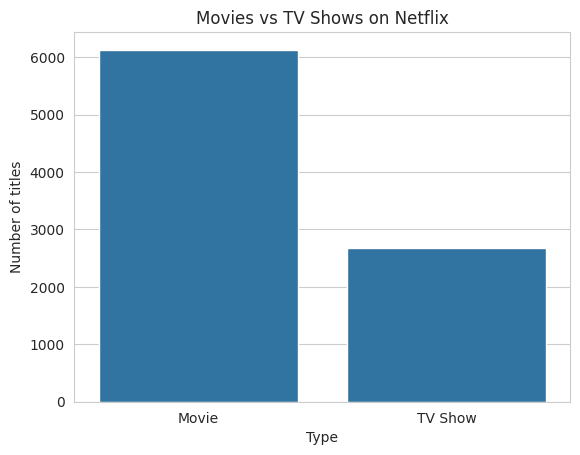

In [42]:
type_share = (df["type"].value_counts(normalize=True) * 100).round(1)
print(type_share)

sns.countplot(data=df, x="type")
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.show()

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

**Finding:** Titles added per year grew from 82 in 2015 to a peak of 2,016 in 2019. The data ends on 25 Sep 2021, so 2021 (1,498 titles) is a partial year and isn't directly comparable.

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")


**Finding:** International Movies (2,752), Dramas (2,427) and Comedies (1,674) are the most common genre tags. A title can carry several tags, so the counts overlap.

type
Movie      69.6
TV Show    30.4
Name: proportion, dtype: float64


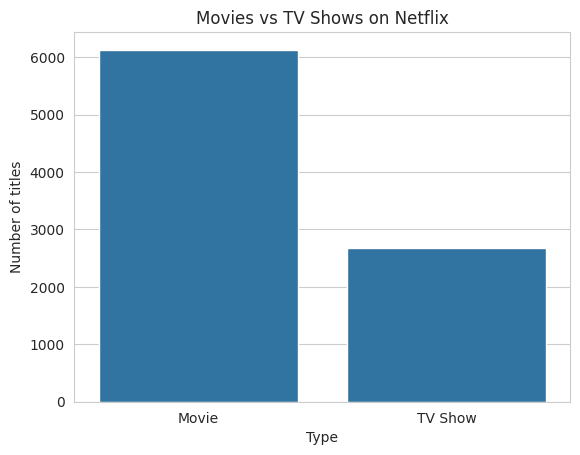

In [45]:
type_share = (df["type"].value_counts(normalize=True) * 100).round(1)
print(type_share)

sns.countplot(data=df, x="type")
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Number of titles")
plt.show()

**Finding:** Among titles with a listed country, the US (3,689) and India (1,046) lead production, followed by the UK, Canada and France. Co-productions count once per country.

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
dtype: int64
Peak year: 2019.0 with 2016 titles added


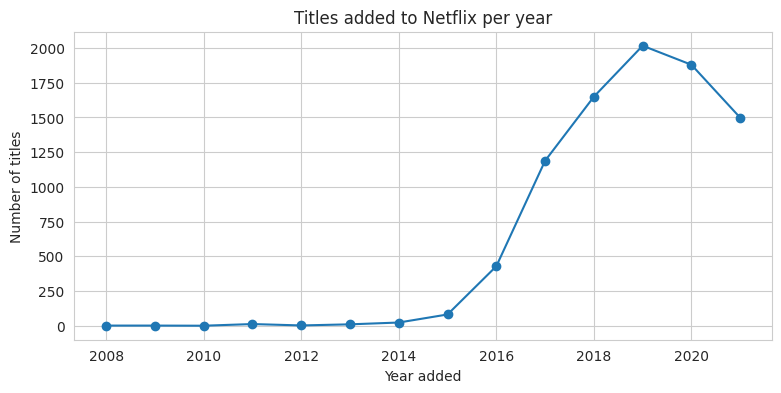

In [46]:
yearly = df.groupby("year_added").size()
print(yearly)
print("Peak year:", yearly.idxmax(), "with", yearly.max(), "titles added")

yearly.plot(marker="o", figsize=(9, 4))
plt.title("Titles added to Netflix per year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.show()

**Finding:** The median movie runs 98 minutes.

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


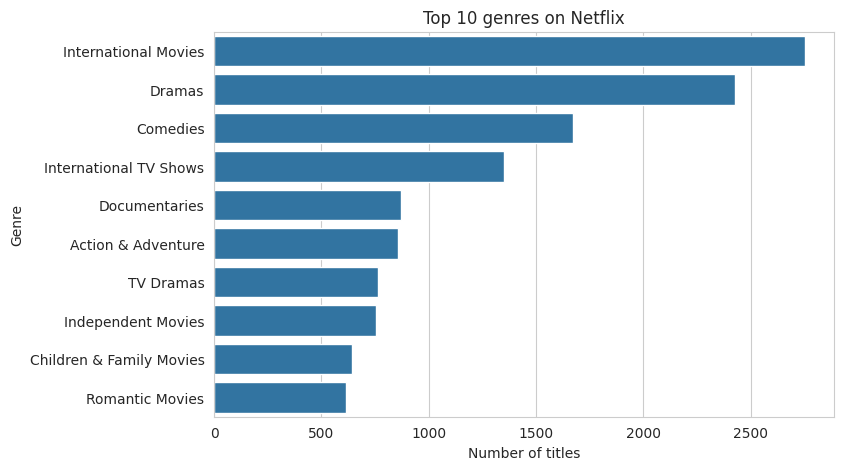

In [47]:
genres = df["listed_in"].str.split(", ").explode().value_counts().head(10)
print(genres)

plt.figure(figsize=(8, 5))
sns.barplot(x=genres.values, y=genres.index)
plt.title("Top 10 genres on Netflix")
plt.xlabel("Number of titles")
plt.ylabel("Genre")
plt.show()


## Summary of findings
1. Movies are about 70% of the 8,800+ titles; TV Shows are about 30%.
2. Titles added per year grew from 82 (2015) to a 2019 peak of 2,016.
3. International Movies, Dramas and Comedies are the top genre tags; the US and India are the top producing countries.
4. The median movie is 98 minutes long.

**Next steps:** build a Power BI dashboard from the cleaned data and add a ratings analysis.

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


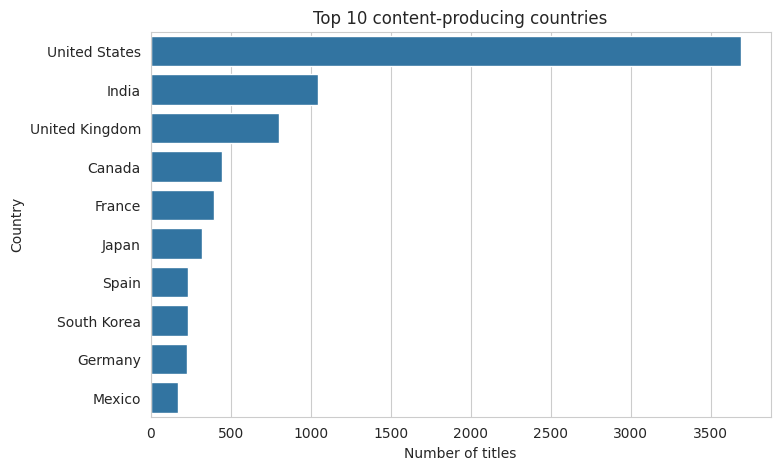

In [48]:
countries = (
    df.loc[df["country"] != "Unknown", "country"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)
print(countries)

plt.figure(figsize=(8, 5))
sns.barplot(x=countries.values, y=countries.index)
plt.title("Top 10 content-producing countries")
plt.xlabel("Number of titles")
plt.ylabel("Country")
plt.show()

In [49]:
df["date_added"].max()

Timestamp('2021-09-25 00:00:00')

Median movie length (min): 98.0


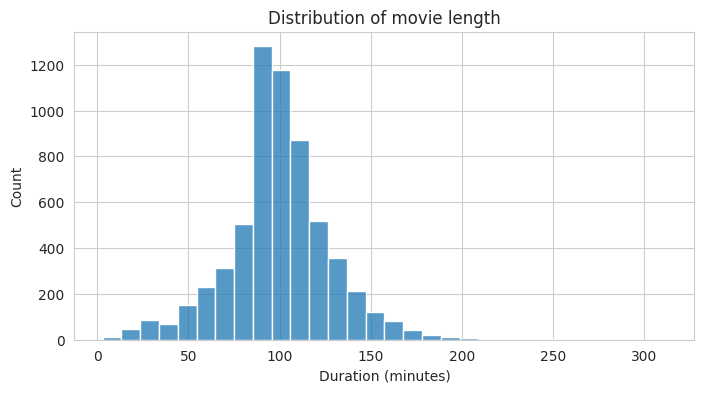

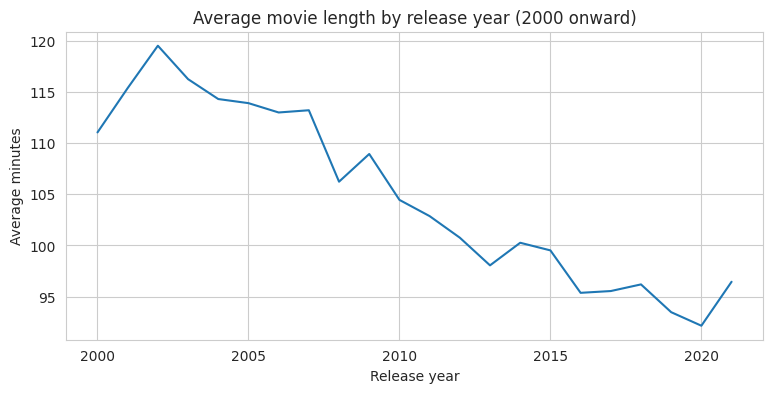

In [50]:
movies = df[df["type"] == "Movie"]
print("Median movie length (min):", movies["duration_num"].median())

plt.figure(figsize=(8, 4))
sns.histplot(movies["duration_num"].dropna(), bins=30)
plt.title("Distribution of movie length")
plt.xlabel("Duration (minutes)")
plt.show()

recent = movies[movies["release_year"] >= 2000]
recent.groupby("release_year")["duration_num"].mean().plot(figsize=(9, 4))
plt.title("Average movie length by release year (2000 onward)")
plt.xlabel("Release year")
plt.ylabel("Average minutes")
plt.show()

In [51]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,3
